
<img src="./img/logo.jpeg">   

# ANÁLISIS EXPLORATORIO DE DATOS - E.D.A. 
**Módulo:** Modelos de Inteligencia Artificial (MIA) — Curso de Especialización en IA y Big Data
**I.E.S. Ribera de Castilla** · Curso 2026-27

Se toma como referencia la guía publicada por el *Gobierno de España* y que analiza los datos relativos a la calidad del aire en Castilla y León. Según se cita en la mencionada guía, la idoneidad de este conjunto de datos radica tanto en su relevancia social como en sus características técnicas, que lo convierten en un caso de estudio ideal para ilustrar las diferentes técnicas de análisis exploratorio.

El AED/EDA se lleva a cabo los siguientes pasos:   

1 - `Realizar un análisis descriptivo de las variables` para obtener una idea representativa del conjunto de datos.   
2 - `Reajustar los tipos de las variables` para que sean consistentes al momento de realizar posteriores operaciones.   
3 - `Detectar y tratar los datos ausentes` para poder procesar adecuadamente las variables numéricas. Los datos ausentes son valores no registrados en algunas observaciones, y es esencial gestionarlos correctamente para evitar sesgos y problemas en el análisis.   
4 - `Identificar datos atípicos y su tratamiento `para evitar que puedan distorsionar futuros análisis estadísticos.   
5 - `Realizar un examen numérico y gráfico de las relaciones entre las variables analizadas` para determinar el grado de correlación entre ellas, pudiendo predecir el comportamiento de una variable en función de las otras.   

<img src="./img/EDA.png">

## PASO 1 . - ANÁLISIS DESCRIPTIVO.    

Después de haber obtenido el correspondiente [dataset](https://datosabiertos.jcyl.es/web/jcyl/risp/es/medio-ambiente/calidad_aire_historico/1284212629698.csv), se lleva a cabo una caracterización inicial de dicho dataset, revisando su estructura y la información que contiene. En este apartado se aplican métodos de estadística descriptiva para analizar las características del dataset y, de forma intuitiva, intentar detectar posibles patrones de distribución de los datos.

#### 1.1 - Carga de librerías necesarias.

In [19]:
import pandas as pd
import os

#### 1.2 - Carga del dataset sobre un dataframe de Pandas.

In [20]:
calidad_aire = pd.read_csv('https://datosabiertos.jcyl.es/web/jcyl/risp/es/medio-ambiente/calidad_aire_historico/1284212629698.csv', sep = ';')

#### 1.3 - Mostrar encabezado/primeras filas del dataframe.

In [21]:
display(calidad_aire.head(5))

,Fecha,CO (mg/m3),NO (ug/m3),NO2 (ug/m3),O3 (ug/m3),PM10 (ug/m3),PM25 (ug/m3),SO2 (ug/m3),Provincia,Estación,Latitud,Longitud,posicion
0,2025-12-21,NaN,1.0,3.0,67.0,5.0,NaN,2.0,Avila,Avila II,40.664722,-4.700833,"40.664722222222224, -4.700833333333334"
1,2025-12-21,NaN,3.0,1.0,78.0,6.0,NaN,NaN,Avila,Olvega,NaN,NaN,NaN
2,2025-12-21,0.8,12.0,24.0,NaN,5.0,NaN,2.0,Burgos,Burgos 6,NaN,NaN,NaN
3,2025-12-21,NaN,5.0,8.0,62.0,8.0,2.0,2.0,Burgos,Miranda de Ebro 2,42.685278,-2.940278,"42.68527777777778, -2.940277777777778"
4,2025-12-21,NaN,2.0,5.0,68.0,2.0,1.0,2.0,Burgos,Aranda de Duero 2,41.665556,-3.688889,"41.66555555555556, -3.688888888888889"


#### 1.4 - Mostrar la estructura del dataframe.

In [22]:
print("="*100)
print(calidad_aire.info())
print("="*100)

<class 'pandas.DataFrame'>
RangeIndex: 515227 entries, 0 to 515226
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Fecha         515227 non-null  str    
 1   CO (mg/m3)    111067 non-null  float64
 2   NO (ug/m3)    478680 non-null  float64
 3   NO2 (ug/m3)   477121 non-null  float64
 4   O3 (ug/m3)    325111 non-null  float64
 5   PM10 (ug/m3)  402260 non-null  float64
 6   PM25 (ug/m3)  70995 non-null   float64
 7   SO2 (ug/m3)   401911 non-null  float64
 8   Provincia     515227 non-null  str    
 9   Estación      515227 non-null  str    
 10  Latitud       510372 non-null  float64
 11  Longitud      510372 non-null  float64
 12  posicion      510372 non-null  str    
dtypes: float64(9), str(4)
memory usage: 51.1 MB
None


#### 1.5 - Resumen estadístico de las variables numéricas

In [23]:
print(calidad_aire.describe())
print("="*100)

          CO (mg/m3)     NO (ug/m3)    NO2 (ug/m3)     O3 (ug/m3)  \
count  111067.000000  478680.000000  477121.000000  325111.000000   
mean        0.809975      12.118229      19.950769      53.404299   
std         0.765878      20.799858      18.453539      22.663999   
min         0.000000    -441.000000       0.000000       0.000000   
25%         0.300000       2.000000       7.000000      38.000000   
50%         0.600000       5.000000      15.000000      55.000000   
75%         1.100000      13.000000      27.000000      69.000000   
max        25.100000     634.000000     249.000000     999.000000   

        PM10 (ug/m3)  PM25 (ug/m3)    SO2 (ug/m3)        Latitud  \
count  402260.000000  70995.000000  401911.000000  510372.000000   
mean       21.654231     12.258215       8.432081      42.125974   
std        17.953505     14.476164      13.167578       0.672736   
min         0.000000      0.000000    -791.000000      38.938333   
25%        10.000000      5.000000    

Por tanto, hasta aquí hemos visto:

• `df.head()`: muestra las primeras filas del DataFrame.   
• `df.info()`: proporciona una vista compacta de la estructura interna del DataFrame, indicando los tipos de variables, el número de valores no nulos y la memoria utilizada.    
• `df.describe()`: muestra un resumen estadístico de las variables numéricas del DataFrame,incluyendo mínimo, máximo, media, mediana, primer y tercer cuartil, y el número de valores faltantes.

La **visualización gráfica de datos** constituye un pilar fundamental en el proceso de análisis exploratorio. Las representaciones visuales no solo complementan los análisis numéricos, sino que además revelan aspectos cruciales de los datos que podrían resultar imperceptibles mediante métodos puramente cuantitativos: patrones de comportamiento, tendencias temporales, relaciones entre variables y potenciales anomalías emergen con claridad a través de las visualizaciones apropiadas.      

El arsenal de herramientas visuales disponible es amplio y versátil, incluyendo ***histogramas*** para el análisis de distribuciones, ***gráficos de líneas*** para la evolución temporal, ***diagramas de barras*** para comparativas categóricas y ***gráficos de sectores*** para análisis composicionales, entre otros.     

La *selección del tipo de visualización* más adecuado para cada análisis resulta crucial y puede profundizarse en esta materia consultando esta guía sobre visualización de datos.

Particularmente, el **histograma** se destaca por su capacidad para representar la *distribución de variables numéricas*. Mediante la agrupación de datos en *intervalos o "bins"*, estos gráficos revelan patrones cruciales en la estructura subyacente de los datos.

La interpretación detallada de un histograma permite identificar diversos aspectos críticos para el análisis posterior:   
• La **tendencia central de los datos**, observable a través de la ubicación del pico o picos de la distribución.    
• La **dispersión o variabilidad**, reflejada en la amplitud y extensión de las barras.     
• La presencia de colas largas o cortas, que pueden indicar la **frecuencia de valores extremos**.     
• Posibles **discontinuidades o gaps en la distribución**, que podrían señalar problemas en la recolección de datos o fenómenos subyacentes importantes.     
• La existencia de **valores atípicos**, visibles como barras aisladas en los extremos de la distribución.

La **forma de la distribución** nos permite realizar la selección de métodos estadísticos posteriores, ya que muchas técnicas asumen normalidad u otras características distribucionales específicas.     
Por ejemplo, una *distribución fuertemente sesgada* podría requerir una transformación de datos o el uso de métodos estadísticos no paramétricos, mientras que una *distribución bimodal* podría sugerir la presencia de subpoblaciones distintas en los datos que merecen un análisis separado.

#### 1.6 Visualización

##### 1.6.1 Importamos librerías

In [24]:
import matplotlib.pyplot as plt
import numpy as np

##### 1.6.2 Seleccionar columnas numéricas

In [25]:
columnas_numericas = calidad_aire.select_dtypes(include=[np.number]).columns

##### 1.6.3 Preparar gráfico.    

Calcular el número de filas y columnas para el subplot

In [26]:
n = len(columnas_numericas)
nrows = 3
ncols = min(n, 3)

Crear el gráfico y los subplots

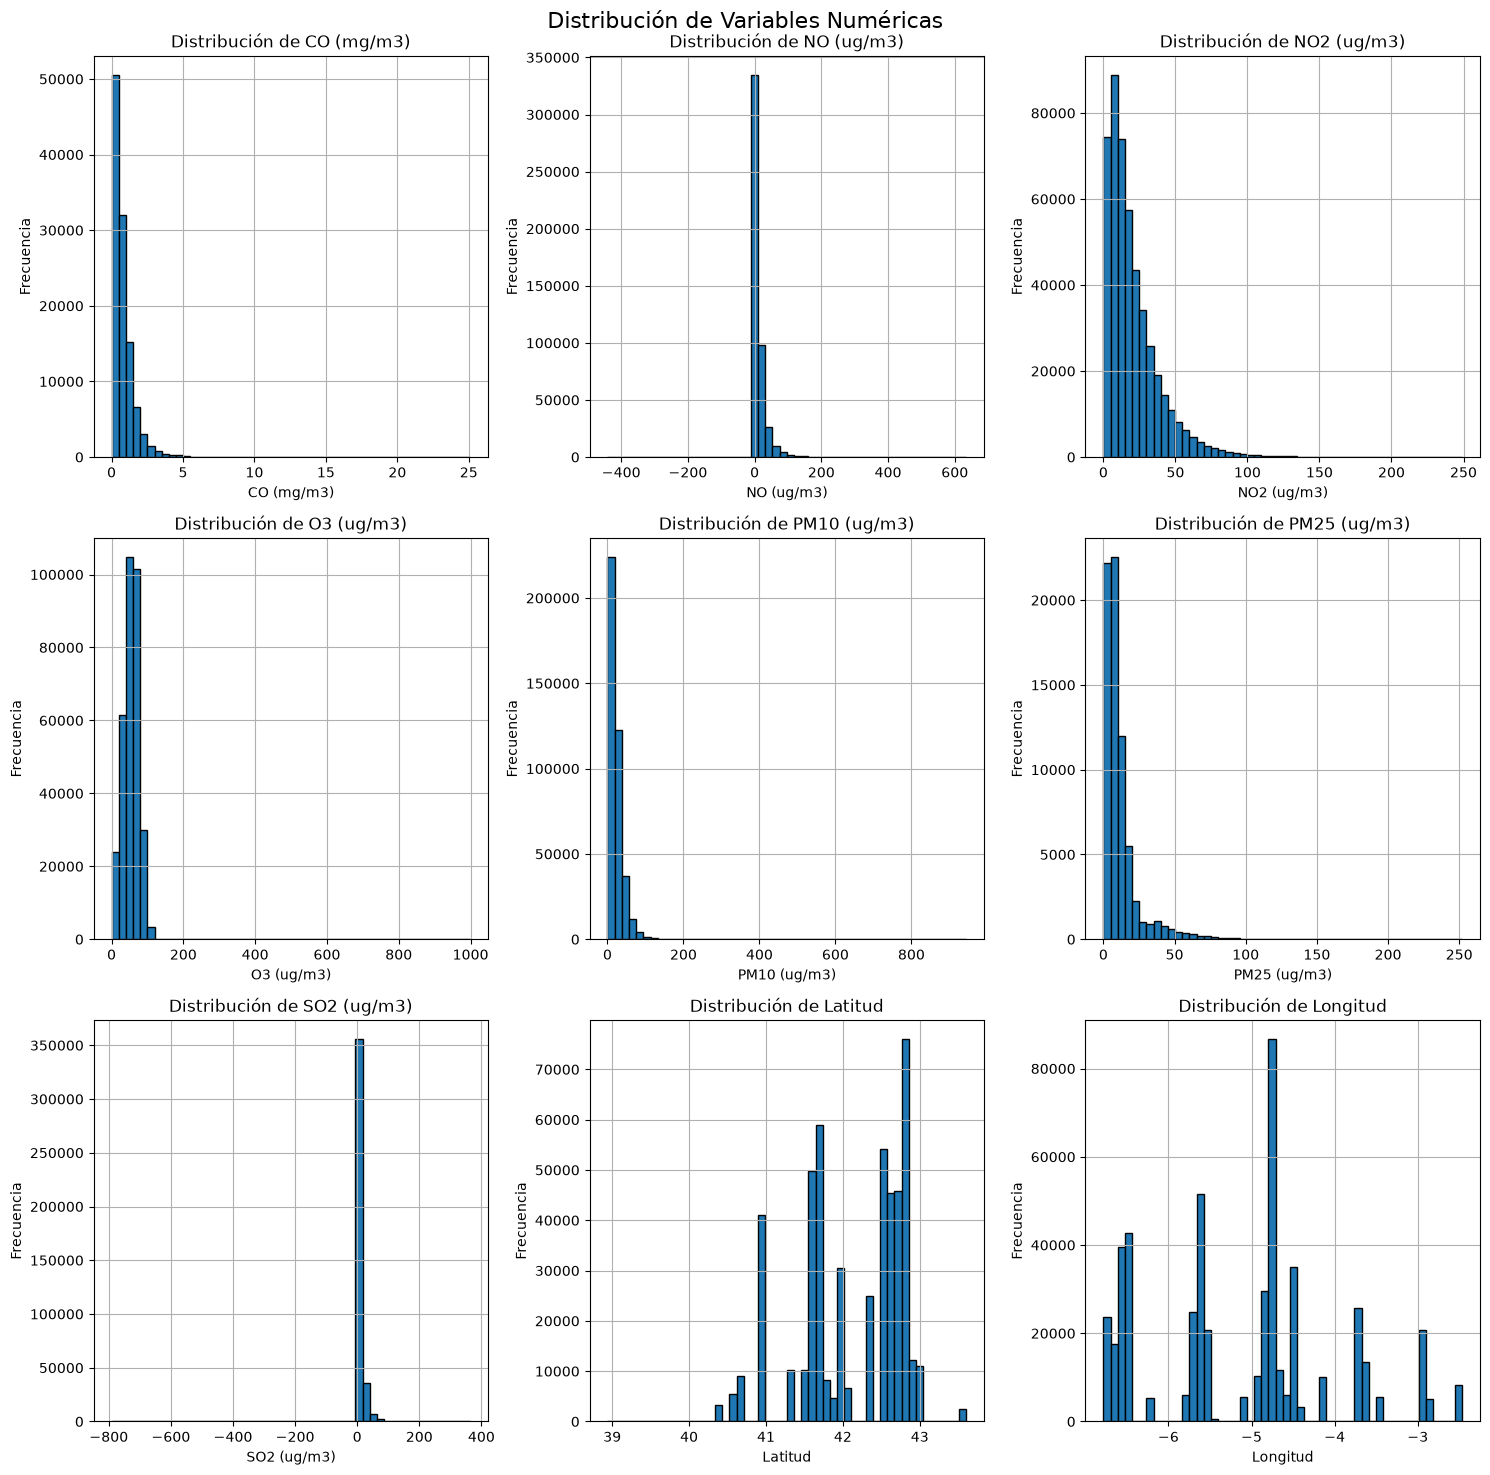

In [27]:
# Crear la figura y los subplots
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 5*nrows))
fig.suptitle('Distribución de Variables Numéricas', fontsize=16)

# Aplanar el array de ejes en caso de que sea 2D
axes = axes.flatten() if n > 3 else [axes]

# Crear histogramas para cada variable numérica
for i, col in enumerate(columnas_numericas):
    ax = axes[i]
    calidad_aire[col].hist(ax=ax, bins=50, edgecolor='black')
    ax.set_title(f'Distribución de {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')

# Ocultar subplots vacíos si los hay
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

En este conjunto de histogramas, resulta particularmente interesante analizar la distribución del NO2(µg/m³).     

Su histograma revela una *distribución claramente asimétrica* con un sesgo positivo pronunciado, donde la mayoría de las mediciones se concentran en valores bajos (por debajo de 50 µg/m³), pero presenta una cola larga hacia la derecha que se extiende hasta aproximadamente 250 µg/m³.    

Esta *distribución es típica de contaminantes atmosféricos en entornos urbanos*, donde se combinan períodos de concentraciones base relativamente bajas con episodios puntuales de alta contaminación, posiblemente asociados a horas pico de tráfico o condiciones meteorológicas específicas.    

La forma de esta distribución sugiere que podría ser necesario aplicar transformaciones logarítmicas para análisis estadísticos posteriores que asuman normalidad, y también indica la importancia de prestar especial atención a esos valores extremos que, aunque menos frecuentes, podrían representar episodios críticos de contaminación desde el punto de vista de la salud pública.      

Explicando este último apartado de forma más detallada tenemos que la afirmación se apoya en lo que se ve en los histogramas de los contaminantes (CO, NO, NO2, PM10, PM2.5, SO2):

1. La forma: asimetría a la derecha

Casi todos tienen la misma forma: una montaña muy alta pegada a la izquierda (valores bajos, que son los más frecuentes) y una cola larga hacia la derecha (valores altos, poco frecuentes). Se llama asimetría positiva.

Es lo esperable en contaminación: la mayor parte del tiempo el aire está relativamente limpio, pero de vez en cuando hay días o horas con concentraciones muy altas (tráfico intenso, inversión térmica, incendios, polvo sahariano...). Además, una concentración no puede bajar de 0, pero sí puede subir mucho, así que la distribución “se estira” solo hacia un lado.

2. ¿Por qué el logaritmo?

Muchos métodos clásicos (t de Student, ANOVA, regresión lineal...) suponen que los datos tienen forma de campana simétrica. Estos datos no la tienen.

El logaritmo *comprime los valores grandes mucho más que los pequeños*: pasar de 10 a 100 y de 100 a 1000 ocupa lo mismo en escala logarítmica. Eso “recoge” la cola larga y suele dejar una distribución mucho más parecida a una campana. Por eso se dice que estos datos se parecen a una *distribución log-normal*.

La alternativa, por ejemplo, sería usar métodos no paramétricos, que no necesitan esa forma de campana.

3. ¿Por qué no hay que despreciar los valores extremos?

En otros contextos, un valor muy alejado se trata como “outlier” y se elimina. Aquí sería un error: esos valores de la cola derecha son precisamente los episodios de contaminación alta, que son los que superan los límites legales y los que más afectan a la salud (problemas respiratorios, cardiovasculares, ingresos hospitalarios). Son poco frecuentes, pero **son lo más relevante** desde el punto de vista de la salud pública.

Finalmente, existen valores en los datos que sería interesante revisar:

- NO y SO2 tienen valores negativos (el eje llega a −400 y −800). Una concentración negativa es físicamente imposible, así que probablemente son errores de medida o códigos de dato inválido. Además, el logaritmo no se puede calcular con valores negativos ni con 0, así que habría que limpiarlos antes **y, si hay ceros, usar np.log1p(x) (que calcula log(1 + x))**.     

- O3 tiene el eje hasta 1000 aunque casi todo está por debajo de 120. Eso indica que hay **algún valor suelto muy alto**, que conviene mirar para decidir si es un episodio real o un error.

## PASO 2. - AJUSTE DE TIPOS DE DATOS.   

Una vez cargado y revisado inicialmente el dataset, se procede a verificar la correcta codificación del tipo de datos para cada variable.      

Un tipo de dato inadecuado puede comprometer análisis posteriores o generar resultados erróneos. Es necesario confirmar que las variables numéricas estén efectivamente almacenadas como números (ya sean enteros o decimales), mientras que las variables cualitativas o categóricas deben estar codificadas como cadenas de caracteres y contener un conjunto finito y bien definido de categorías.    

A tener en consideración:    

• Las **variables temporales (fechas)** requieren un tratamiento especial que permita capturar la naturaleza secuencial y las propiedades cíclicas del tiempo.    
• Las **variables categóricas** deben preservar la estructura jerárquica o nominal de sus categorías.     
• Los **datos numéricos** deben mantener sus propiedades matemáticas y estadísticas.

En este dataset, la variable `Fecha` requiere una conversión a tipo fecha (`datetime`) para permitir operaciones temporales como cálculo de intervalos, agregaciones por períodos o análisis de estacionalidad. La transformación mediante `pd.to_datetime()`, no solo cambia el formato, sino que habilita todo el
ecosistema de análisis temporal de Python.   

Las variables `Provincia` y `Estación` representan variables categóricas, cuya conversión a `type('category')` optimiza tanto el uso de memoria como el rendimiento computacional. Este tipo de datos es especialmente relevante en el análisis exploratorio ya que:   

1. Facilita la detección de categorías incorrectas o anomalías.
2. Permite operaciones eficientes de agrupación y filtrado.
3. Habilita análisis específicos para variables categóricas como tablas de contingencia.
4. Optimiza la generación de visualizaciones categóricas.   

El procedimiento a seguir es reajustar los tipos de estas variables para poder realizar posteriormente las operaciones, análisis y representaciones gráficas que sean necesarias.    

Visualizamos el tipo de dato con el que se ha cargado inicialmente cada una de estas columnas:

In [28]:
print(calidad_aire["Fecha"].head())

0    2025-12-21
1    2025-12-21
2    2025-12-21
3    2025-12-21
4    2025-12-21
Name: Fecha, dtype: str


In [29]:
print(calidad_aire['Provincia'].head())

0     Avila
1     Avila
2    Burgos
3    Burgos
4    Burgos
Name: Provincia, dtype: str


In [30]:
print(calidad_aire['Estación'].head())

0             Avila II
1               Olvega
2             Burgos 6
3    Miranda de Ebro 2
4    Aranda de Duero 2
Name: Estación, dtype: str


A continuación, procedemos a realizar los ajustes a los tipos de datos más adecuados para dichas variables.

##### 2.1- Ajustar el tipo de la variable Fecha

In [31]:
calidad_aire['Fecha'] = pd.to_datetime(calidad_aire['Fecha'], errors='coerce')

##### 2.2- Ajustar el tipo de la variable Provincia

In [32]:
print(calidad_aire['Provincia'].unique())
calidad_aire['Provincia'] = calidad_aire['Provincia'].astype('category')

<StringArray>
[     'Avila',     'Burgos',       'León',   'Palencia',  'Salamanca',
    'Segovia',      'Soria', 'Valladolid',     'Zamora',     'Madrid']
Length: 10, dtype: str


##### 2.3 - Ajustar el tipo de la variable Estación

In [33]:
print(calidad_aire['Estación'].unique())
calidad_aire['Estación'] = calidad_aire['Estación'].astype('category')

<StringArray>
[                        'Avila II',                           'Olvega',
                         'Burgos 6',                'Miranda de Ebro 2',
                'Aranda de Duero 2',                         'Burgos 4',
                  'Medina de Pomar',                            'Lario',
                           'Leon 4',                      'Carracedelo',
            'Cubillos del Sil-FESE',                         'La Robla',
                            'Otero',                            'Leon1',
                      'Ponferrada6',               'Toral de los Vados',
      'Tudela Veguin-Tudela Veguin',                         'Valderas',
                           'Guardo',                       'Palencia 3',
             'Hontoria 1 - Poblado',                         'Renault4',
      'Hontoria 2 - Venta de Baños',                        'El Maillo',
                       'Salamanca5',                       'Salamanca6',
                        'Segovia 2', 

## PASO 3. DETECCIÓN Y TRATAMIENTO DE VALORES AUSENTES.   

La presencia de **datos ausentes**, también conocidos como missing values, `NaN` (Not a Number) en Python, es una situación común en muchos conjuntos de datos y puede representar un desafío significativo en el análisis de datos. Estos valores faltantes pueden surgir por diversas razones, como errores durante la
transcripción de datos, problemas en el proceso de recolección, o incluso porque ciertos valores no estaban disponibles en el momento de la medición.   

La gestión adecuada de los datos ausentes es crucial para garantizar la calidad y la fiabilidad del análisis estadístico. Los datos faltantes pueden distorsionar los resultados de los análisis, afectar la precisión de los modelos predictivos y alterar las visualizaciones gráficas, llevando a interpretaciones incorrectas o
engañosas. 

##### 3.1 - Comprobamos datos ausentes.

In [34]:
# Devuelve un DataFrame booleano
calidad_aire.isna()

,Fecha,CO (mg/m3),NO (ug/m3),NO2 (ug/m3),O3 (ug/m3),PM10 (ug/m3),PM25 (ug/m3),SO2 (ug/m3),Provincia,Estación,Latitud,Longitud,posicion
0,False,True,False,False,False,False,True,False,False,False,False,False,False
1,False,True,False,False,False,False,True,True,False,False,True,True,True
2,False,False,False,False,True,False,True,False,False,False,True,True,True
3,False,True,False,False,False,False,False,False,False,False,False,False,False
4,False,True,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
515222,False,False,False,False,False,True,True,False,False,False,False,False,False
515223,False,False,False,False,False,False,True,False,False,False,False,False,False
515224,False,False,False,False,False,False,True,False,False,False,False,False,False
515225,False,True,False,False,False,True,True,True,False,False,False,False,False


In [ ]:
# Devuelve True si hay al menos un valor ausente
calidad_aire.isna().any().any() # .any() devuelve True si hay al menos un valor ausente en el DataFrame

np.True_

In [ ]:
# Devuelve el número total de NaN que presenta el DataFrame
print(calidad_aire.isna().sum().sum()) # .isna() comprueba si hay valores ausentes.

1354009


In [38]:
# Devuelve el % de valores perdidos
print(calidad_aire.isna().mean().mean() * 100)

20.215271804765365


In [39]:
# Detección del número de valores perdidos en cada una de las columnas
calidad_aire.isna().sum()

Fecha                0
CO (mg/m3)      404160
NO (ug/m3)       36547
NO2 (ug/m3)      38106
O3 (ug/m3)      190116
PM10 (ug/m3)    112967
PM25 (ug/m3)    444232
SO2 (ug/m3)     113316
Provincia            0
Estación             0
Latitud           4855
Longitud          4855
posicion          4855
dtype: int64

In [41]:
# Detección del % de valores perdidos en cada una de las columnas
calidad_aire.isna().mean().round(2) * 100

Fecha            0.0
CO (mg/m3)      78.0
NO (ug/m3)       7.0
NO2 (ug/m3)      7.0
O3 (ug/m3)      37.0
PM10 (ug/m3)    22.0
PM25 (ug/m3)    86.0
SO2 (ug/m3)     22.0
Provincia        0.0
Estación         0.0
Latitud          1.0
Longitud         1.0
posicion         1.0
dtype: float64

La distribución de estos valores perdidos no es uniforme entre las variables, destacando especialmente la ausencia de datos en los parámetros de CO (mg/m³) y PM25 (µg/m³), con un 78% y 86% de valores faltantes respectivamente.      

La magnitud y naturaleza de estos datos faltantes plantea un desafío metodológico significativo que debe abordarse cuidadosamente para garantizar la validez y utilidad del análisis posterior.      

La gestión de estos valores ausentes requerirá una estrategia que equilibre la preservación de la integridad de los datos con la necesidad de mantener un conjunto de datos suficientemente completo para su análisis y reutilización efectiva.

### 3.2 - Tratamiento de datos ausentes    

El manejo de valores ausentes es un aspecto crucial en la preparación de datos. Existen diversas estrategias para tratar con datos faltantes, cada una con sus ventajas y desventajas. A continuación, se describen algunas de las técnicas más comunes:     

- Rellenar con estadísticos descriptivos:    
    - **Media**: sustituir los valores ausentes con la media de la variable. Es útil cuando los datos están distribuidos normalmente y no hay muchos valores faltantes.    
    - **Mediana**: usar la mediana es una buena opción si los datos son asimétricos o contienen valores atípicos, ya que es menos sensible a estos extremos que la media.     
    - **Moda**: reemplazar con el valor más frecuente es adecuado para variables categóricas.     

- Rellenar por valores adyacentes:    
    - **Imputación** por delante o detrás: completar los valores faltantes con el valor de la fila o columna anterior o siguiente. Este método es útil en series temporales donde los datos suelen ser correlacionados en el tiempo.

- Rellenar con cero:    
    - **Asignación de cero**: para valores numéricos, rellenar con cero puede ser simple, pero es generalmente desaconsejado, ya que puede introducir sesgo significativo y alterar los resultados.   

- Eliminar filas:    
    - **Eliminación de filas**:si los datos faltantes están presentes en un número pequeño de filas y el conjunto de datos es grande, se pueden eliminar estas filas. Esta técnica puede ser útil para evitar la imputación, pero se debe tener cuidado de no perder información valiosa.    

- Imputación con algoritmos de machine learning:     
    - **Modelos predictivos**: utilizar algoritmos para predecir los valores faltantes basados en otros datos. Esta técnica puede proporcionar imputaciones más precisas, pero es más compleja y computacionalmente intensiva.      

- Eliminar variables:    
    - **Variables con alta tasa de datos faltantes**: en algunos casos, puede ser apropiado eliminar variables que tengan más del 50% de datos ausentes, especialmente si la variable es poco relevante para el análisis.

La selección de la técnica de tratamiento adecuada *depende del tipo de datos, la cantidad y patrón de los datos faltantes, y el contexto del análisis*. Aunque la imputación por media es una técnica común, no siempre es la más adecuada. Es esencial **evaluar cómo cada método puede afectar a los resultados** y la calidad del análisis final.    

Además, es importante ***documentar cuidadosamente cualquier decisión tomada en el tratamiento de datos ausentes***. Un diseño riguroso del AED incluye la trazabilidad de estos procesos para poder evaluar su impacto y hacer ajustes si se detectan inconsistencias o debilidades en etapas posteriores del análisis.

En nuestro caso, el primer tratamiento que se va a realizar sobre los datos perdidos es la eliminación de las dos variables que presentan un porcentaje superior al 50%, ya que un número de `NaN` tan alto puede producir errores o distorsionar los análisis posteriores al no ser usadas las filas que presentan `NaN` (en este caso, no se usaría más del 50% de las observaciones). Antes, se guarda una copia del dataset original.

##### 3.2.1 - Selección y eliminación de las columnas más críticas.

In [43]:
# Guardar dataset original
calidad_aire_original = calidad_aire.copy()

# Eliminación de las variables que presentan un % de NaN superior al 50%
calidad_aire = calidad_aire.loc[:, calidad_aire.isna().mean() < 0.5]
print(f" Tras esta operación, contamos con {len(calidad_aire.columns)} columnas")

 Tras esta operación, contamos con 11 columnas


##### 3.2.2 - Tratamiento de las columnas numéricas para cargar valores faltantes con el valor de la **media** de cada columna.

In [ ]:
# Seleccionamos las variables numéricas
columnas_numericas = calidad_aire.select_dtypes(include=[np.number]).columns

# Calculamos la media para cada una de las variables numéricas sin tener en cuenta los NaN
cols_mean = calidad_aire[columnas_numericas].mean()

# Sustituimos los valores NaN por la media correspondiente a cada variable
calidad_aire[columnas_numericas] = calidad_aire[columnas_numericas].fillna(cols_mean)

Es importante señalar que el tratamiento realizado, aunque válido como ejemplo ilustrativo, representa una aproximación simplificada al problema de los valores ausentes. En un análisis más exhaustivo de datos de calidad del aire, deberían considerarse aspectos adicionales como:     

- La **naturaleza temporal de las mediciones**: los contaminantes atmosféricos suelen presentar patrones diarios y estacionales, por lo que la imputación por media simple podría no capturar estas variaciones cíclicas. Una aproximación más sofisticada podría considerar la imputación basada en medias móviles o valores de períodos temporales equivalentes.    

- La **correlación espacial**: dado que los datos provienen de diferentes estaciones de medición, sería relevante considerar la proximidad geográfica entre estaciones para la imputación de valores ausentes, ya que estaciones cercanas tienden a registrar niveles similares de contaminación.     

- El **contexto meteorológico**: la concentración de contaminantes está fuertemente influenciada por variables meteorológicas como la temperatura, precipitación, dirección y velocidad del viento. Un método de imputación más robusto podría incorporar estas variables como predictores.     

- El **patrón de ausencia**: antes de eliminar variables con alto porcentaje de valores ausentes, sería conveniente analizar si estos siguen algún patrón sistemático (por ejemplo, fallos específicos de sensores o períodos de mantenimiento) que pudiera aportar información relevante sobre la calidad de los datos.

## PASO 4. DETECCIÓN Y TRATAMIENTO DE DATOS ATÍPICOS (OUTLIERS)       

Un **valor atípico** u **outlier** representa una observación que exhibe una desviación significativa respecto al patrón general de comportamiento del resto de los datos. Estas observaciones extremas pueden surgir por diversos motivos: desde errores en la medición o registro de datos hasta fenómenos reales pero
extraordinarios que merecen especial atención.      

Su importancia en el análisis exploratorio es crucial, ya que pueden ejercer una influencia desproporcionada en los estadísticos descriptivos, distorsionar las relaciones entre variables y comprometer la validez de modelos estadísticos posteriores.    

La gestión adecuada de estos valores requiere un equilibrio entre la preservación de información potencialmente valiosa y la necesidad de mantener la robustez del análisis estadístico.

El enfoque más común para el manejo de outliers es reducir su posible influencia en los análisis. A continuación, se mencionan algunas estrategias que se pueden considerar:

• *Métodos estadísticos robustos*: existen técnicas estadísticas robustas diseñadas para minimizar el impacto de los valores atípicos en los resultados. Estos métodos ajustan el análisis para que sea menos sensible a los outliers, preservando así la integridad de los resultados.    

• *Eliminación de outliers*: eliminar valores atípicos puede ser apropiado en algunos casos, pero debe hacerse con cuidado. Antes de descartar un outlier, es fundamental verificar si el valor es el resultado de un error de medición o de un problema en la construcción del dataset.     

• *Sustitución de outliers*: reemplazar outliers por la media o la mediana, por ejemplo. Aunque esta práctica puede parecer una solución sencilla, puede alterar la distribución y la varianza de los datos, introduciendo sesgo en el análisis.

Si se decide eliminar o sustituir los valores atípicos, **es prudente repetir los análisis** tanto con los valores originales como con los datos modificados. Esto permite observar el impacto real de los outliers en los resultados.      
Si la diferencia es mínima, puede ser razonable proceder con la eliminación o sustitución. Sin embargo, si el impacto es considerable, se debe justificar adecuadamente cualquier decisión.

A continuación, se muestra cómo se pueden detectar y eliminar los valores atípicos, suponiendo que se puede justificar que los valores son errores de medición o problemas derivados de la ingesta de datos. El objetivo es evitar que estos valores distorsionen futuros análisis estadísticos.   

Para empezar, debemos distinguir dos tipos de tratamiento en función del tipo de variables: *continuas o discretas* y *categóricas*.   

### 4.1 Tratamiento valores atípicos de variables continuas/discretas.    

Para mostrar el proceso de detección de valores atípicos en una variable continua, utilizaremos como ejemplo la variable numérica ‘O3 (µg/m³)’. El proceso es exactamente igual para el resto de las variables numéricas que presente la tabla.     

En primer lugar, *generamos un histograma* para conocer la distribución de frecuencias que presenta la variable de estudio:

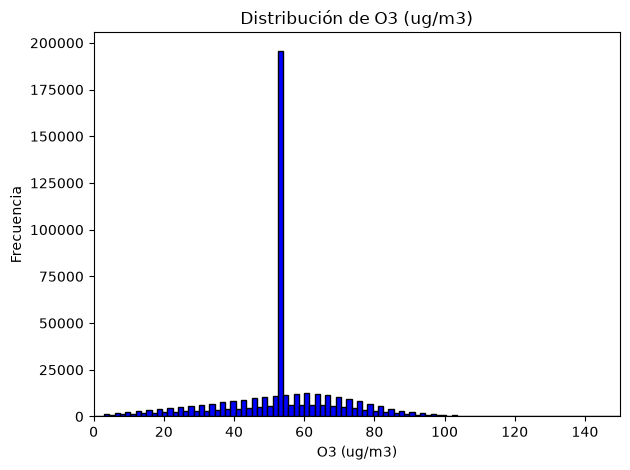

In [44]:
plt.hist(calidad_aire['O3 (ug/m3)'], bins=100, range=(0, 150), color='blue', edgecolor='black')
plt.title('Distribución de O3 (ug/m3)')
plt.xlabel('O3 (ug/m3)')
plt.ylabel('Frecuencia')
plt.xlim(0,150)
plt.tight_layout()
plt.show()

El histograma de **O3** revela una distribución asimétrica positiva característica de mediciones de contaminantes atmosféricos, donde la mayoría de las observaciones se concentran en el rango de 0 a 100 µg/m³.       

Las observaciones que superan este umbral presentan una frecuencia marcadamente inferior, sugiriendo la presencia de valores potencialmente atípicos. Sin embargo, en el contexto de la calidad del aire, estos valores elevados podrían representar episodios reales de alta concentración de ozono, típicamente asociados a condiciones meteorológicas específicas como alta radiación solar y temperatura elevada, especialmente durante los meses estivales.      

Para detectar de forma más adecuada la presencia de valores atípicos, utilizaremos la representación más adecuada para esta tarea: un ***gráfico de cajas y bigotes***(boxplot).

Los **gráficos de cajas y bigotes o boxplots** aportan una representación visual que describe la dispersión y simetría que presentan los datos observando los cuartiles (división de la distribución en cuatro partes delimitadas por los valores 0,25; 0,50 y 0,75).     

Estos gráficos están compuestos por tres componentes:     

1. *Caja de rango intercuartílico* (interquartile range o IQR): representa el 50% de los datos, comprende desde el percentil 25 de la distribución (Q1), hasta el percentil 75 (Q3). Dentro de la caja encontramos una línea que señala el percentil 50 de la distribución (Q2), la **mediana**. La caja aporta una idea sobre la dispersión de la distribución en *función de la separación existente entre Q1 y Q3*, así como también *si la distribución es simétrica en torno a la mediana* o *si está sesgada hacia alguno de los lados*.    

2. *Bigotes*: se extienden desde ambos lados de los extremos de la caja y representan los rangos del 25% de valores de la parte inferior (Q1 – 1,5 IQR) y el 25% de valores de la parte superior (Q3 + 1,5 IQR), excluyendo los valores atípicos.     

3. *Valores atípicos*: esta representación *identifica como valores atípicos* aquellas observaciones que presentan **valores inferiores o superiores a los límites del gráfico** (límite inferior: Q1 – 1,5 IQR y límite superior: Q3 + 1,5 IQR).

Estadísticas para O3:
Q1 - 1.5IQR = 32.50
Q1 = 49.00
Mediana = 53.40
Q3 = 60.00
Q3 + 1.5IQR = 76.50
Número de observaciones: 515227
Número de outliers: 103356


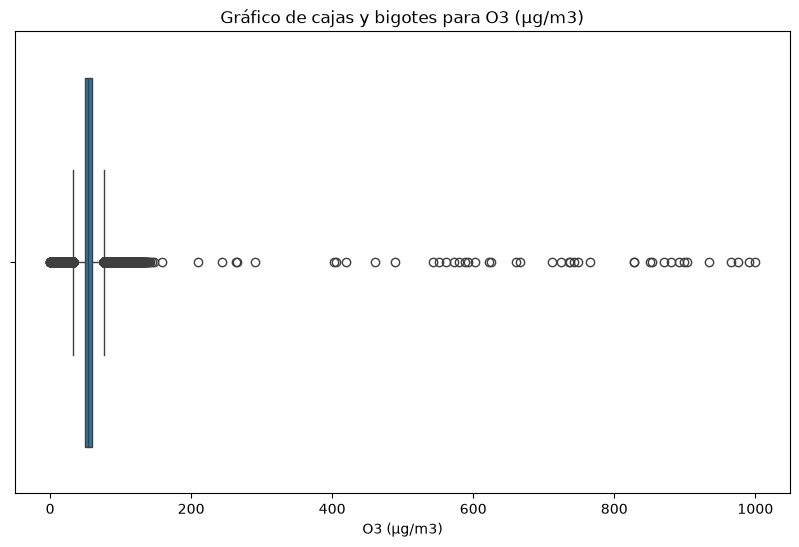

In [45]:
# Importamos la librería seaborn para la visualización de datos
import seaborn as sns

# Estadísticas necesarias para reproducir el gráfico de cajas y bigotes
Q1 = calidad_aire['O3 (ug/m3)'].quantile(0.25)
Q3 = calidad_aire['O3 (ug/m3)'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Estadísticas para O3:")
print(f"Q1 - 1.5IQR = {lower_bound:.2f}")
print(f"Q1 = {Q1:.2f}")
print(f"Mediana = {calidad_aire['O3 (ug/m3)'].median():.2f}")
print(f"Q3 = {Q3:.2f}")
print(f"Q3 + 1.5IQR = {upper_bound:.2f}")
print(f"Número de observaciones: {len(calidad_aire['O3 (ug/m3)'])}")
print(f"Número de outliers: {sum((calidad_aire['O3 (ug/m3)'] < lower_bound) | (calidad_aire['O3 (ug/m3)'] > upper_bound))}")

# Construcción del gráfico de cajas y bigotes
plt.figure(figsize=(10, 6))
sns.boxplot(x=calidad_aire['O3 (ug/m3)'])
plt.title('Gráfico de cajas y bigotes para O3 (µg/m3)')
plt.xlabel('O3 (µg/m3)')
plt.show()

Los datos que arroja este análisis sobre la variable `O3` revela patrones interesantes en su distribución. Los estadísticos descriptivos muestran una mediana de 53.40 µg/m³, con un rango intercuartílico (IQR) que va desde 32.50 µg/m³ (Q1) a 76.50 µg/m³ (Q3).      

El diagrama de cajas y bigotes ilustra una *marcada presencia de valores atípicos por encima del límite superior*, identificándose específicamente 103.356 observaciones que superan este umbral sobre un total de 515.227 mediciones (aproximadamente un 20% de los datos).

### 4.2 Tratamiento valores atípicos de variables categóricas.     

La *detección de valores atípicos en variables categóricas* requiere un enfoque diferente al utilizado en variables numéricas, centrándose en la identificación de categorías inusuales o inconsistentes con el dominio del problema. Para este análisis, la visualización mediante gráficos de barras o diagramas de frecuencia resulta especialmente útil, ya que **permite identificar tanto la distribución de las categorías esperadas como la posible presencia de categorías anómalas** que podrían representar errores de codificación, problemas en la recolección de datos o casos especiales que requieran atención.    

En este caso, se utiliza la variable 'Provincia' como ejemplo ilustrativo de este proceso. Esta elección resulta particularmente adecuada ya que las categorías válidas están claramente definidas (las provincias de Castilla y León), lo que facilita la identificación de posibles anomalías como errores ortográficos, variaciones en el formato de escritura, o la presencia de provincias que no pertenezcan a la comunidad autónoma. Este mismo procedimiento de análisis puede y debe aplicarse a cualquier variable categórica del conjunto de datos, adaptando los criterios de validación según la naturaleza específica de cada variable.   

En Python, podemos utilizar la librería matplotlib o seaborn para crear gráficos de barras y visualizar la distribución de las categorías.

In [46]:
# Número de categorías que presenta la variable Provincia
categoria_counts = calidad_aire['Provincia'].value_counts()

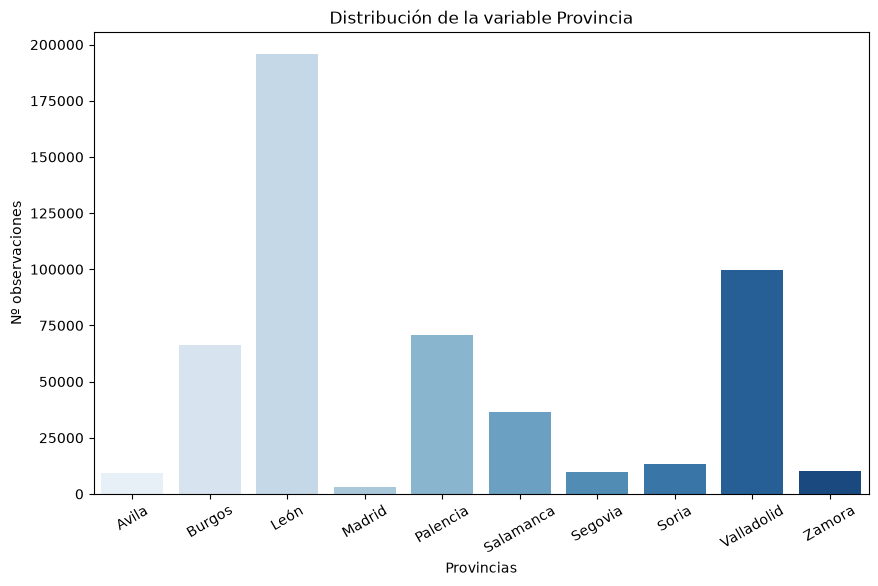

In [49]:

# Construcción del gráfico de barras para la variable Provincia
plt.figure(figsize=(10, 6))
sns.barplot(x=categoria_counts.index, y=categoria_counts.values, palette='Blues', hue=categoria_counts.index, legend=False, dodge=False)
plt.xlabel('Provincias')
plt.ylabel('Nº observaciones')
plt.xticks(rotation=30)
plt.title('Distribución de la variable Provincia')
plt.show()

En este caso, queda bastante claro que la categoría `Madrid` es un valor atípico dentro de la variable 'Provincia', ya que no pertenece a la Comunidad Autónoma de Castilla y León. 

Por tanto, podemos eliminar esta categoría de nuestros datos.

### 4.3 - Eliminación de valores atípicos de variables continuas.     

Una vez identificados los valores atípicos, procedemos a eliminarlos. Una forma de eliminar los valores atípicos de una variable numérica es *generar una nueva tabla*.

In [50]:
# Se genera una nueva tabla que no contiene los valores identificados como atípicos
calidad_aire_NoOut = calidad_aire[(calidad_aire['O3 (ug/m3)'] >= lower_bound) &
(calidad_aire['O3 (ug/m3)'] <= upper_bound)]

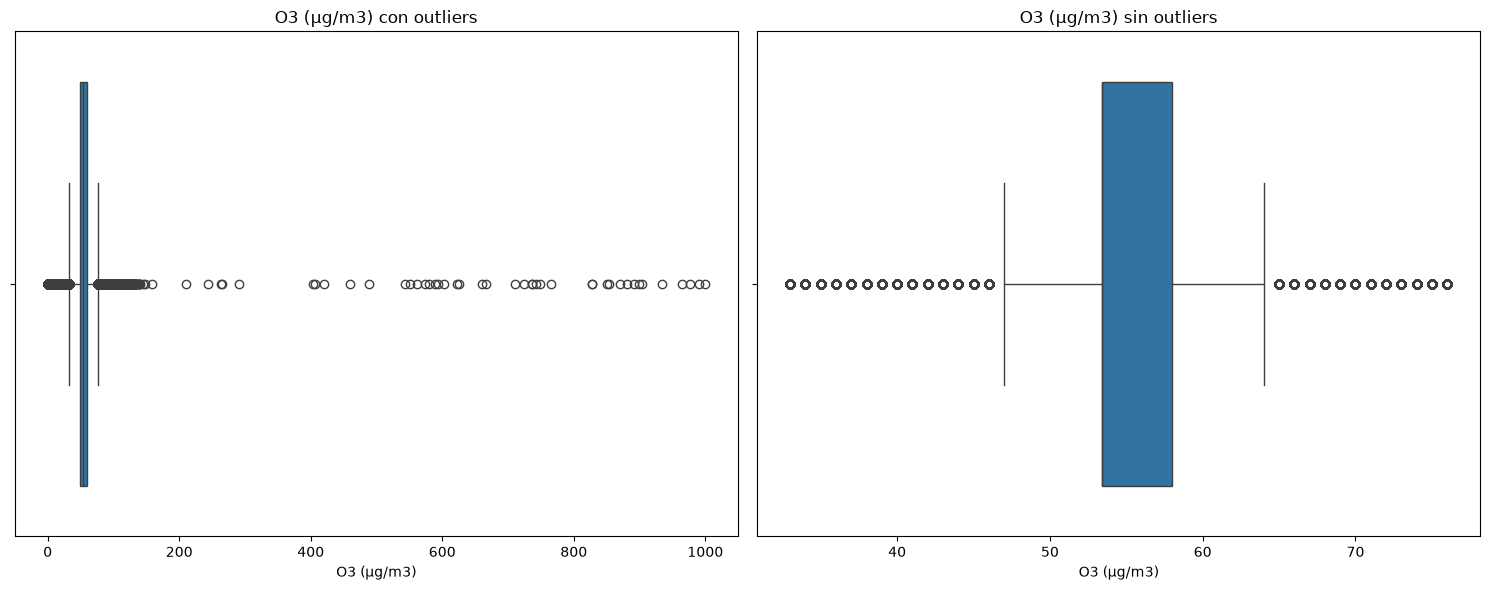

In [51]:
# Construcción de los gráficos de cajas y bigotes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(x=calidad_aire['O3 (ug/m3)'], ax=ax1)
ax1.set_title('O3 (µg/m3) con outliers')
ax1.set_xlabel('O3 (µg/m3)')

sns.boxplot(x=calidad_aire_NoOut['O3 (ug/m3)'], ax=ax2)
ax2.set_title('O3 (µg/m3) sin outliers')
ax2.set_xlabel('O3 (µg/m3)')

plt.tight_layout()
plt.show()

La comparación de los diagramas de cajas y bigotes antes y después de la eliminación de valores atípicos muestra cambios significativos en la distribución de la variable O3 (µg/m³). El gráfico posterior a la eliminación muestra una distribución más compacta y simétrica, con un rango considerablemente más reducido que oscila aproximadamente entre 30 y 70 µg/m³.     

Este cambio en la escala permite apreciar mejor la estructura central de los datos, donde tanto la mediana como los cuartiles se visualizan con mayor claridad.

### 4.4 - Eliminación de valores atípicos de variables categóricas.     

Para deshacernos de las variables categóricas podemos utilizar el método `drop()` para eliminar filas que contienen la categoría atípica y `astype('category').cat.remove_unused_categories()` para asegurarnos de que la categoría se elimina del tipo de dato categórico.

In [52]:
# Creamos una copia explícita del DataFrame excluyendo las filas de Madrid
calidad_aire_SM = calidad_aire[calidad_aire['Provincia'] != 'Madrid'].copy()

In [53]:
# Eliminamos las categorías no utilizadas
calidad_aire_SM['Provincia'] = calidad_aire_SM['Provincia'].astype('category').cat.remove_unused_categories()

In [54]:

# Verificamos la eliminación de la categoría "Madrid"
print(calidad_aire_SM['Provincia'].cat.categories)

Index(['Avila', 'Burgos', 'León', 'Palencia', 'Salamanca', 'Segovia', 'Soria',
       'Valladolid', 'Zamora'],
      dtype='str')


## PASO 5 - CORRELACIÓN ENTRE VARIABLES.    

La **correlación (r)** mide la relación lineal entre dos o más variables, reflejando tanto la fuerza como la dirección de su relación. En términos simples, **la correlación nos indica si dos variables cambian juntas y de qué manera lo hacen**:   
- ***Correlación positiva***: si una variable aumenta y la otra también lo hace, se dice que están correlacionadas positivamente. Un valor de (r) cercano a +1 indica una relación positiva fuerte.   
- ***Correlación negativa***: si una variable aumenta mientras que la otra disminuye, están correlacionadas negativamente. Un valor de (r) cercano a -1 indica una relación negativa fuerte.     
- ***Sin correlación***: un valor de (r) cercano a 0 sugiere que no hay una relación lineal clara entre las variables.     

Es importante señalar que la *correlación de Pearson*, siendo la más común, no es la única medida de correlación disponible. Existen alternativas como:   
- La **correlación de Spearman**, más robusta frente a valores atípicos y útil para relaciones monótonas no lineales.    
- La **correlación de Kendall**, especialmente útil para muestras pequeñas y cuando los datos no siguen una distribución normal.
- **Medidas de correlación basadas en rangos**, que pueden capturar relaciones no lineales entre variables.

El análisis de correlación puede ser útil en varios aspectos:   

- *Identificación de redundancia*: puede ayudar a identificar variables redundantes en un conjunto de datos. Si dos variables están altamente correlacionadas, una de ellas podría ser eliminada sin perder información significativa, lo que simplifica el análisis y el procesamiento de datos.
- *Simplicidad en el análisis*: en el contexto del AED, entender las correlaciones entre variables puede guiar la selección de variables para modelos predictivos y otros análisis estadísticos.
- *Relación con PCA*: el análisis de correlación está relacionado con técnicas como el *Análisis de Componentes Principales (PCA)*. PCA utiliza la matriz de correlación para transformar las variables originales en un nuevo conjunto de variables, llamadas componentes principales, que capturan la mayor variabilidad en los datos.

En el caso específico de datos ambientales y calidad del aire, el análisis de correlación cobra especial relevancia al permitir una comprensión holística de las interacciones entre contaminantes y su entorno.   

Esta técnica resulta fundamental para identificar relaciones entre diferentes contaminantes que comparten fuentes de emisión comunes, al tiempo que facilita el entendimiento de cómo las condiciones meteorológicas influyen en sus concentraciones.     

Adicionalmente, este análisis permite detectar patrones temporales y espaciales en la distribución de contaminantes, proporcionando una base sólida para la interpretación de la dinámica atmosférica y la gestión efectiva de la calidad del aire.

El análisis de correlación es una ***herramienta fundamental*** en la exploración multivariante de datos, pero presenta limitaciones que deben ser consideradas, como coeficientes significativamente distorsionados por la presencia de valores atípicos o la potencial omisión de relaciones no lineales y patrones complejos. 

Para abordar estas limitaciones, resulta imprescindible complementar el análisis con herramientas adicionales como el uso de visualizaciones de dispersión que permitan detectar patrones no lineales, la realización de análisis estratificado por subgrupos para identificar posibles heterogeneidades en las relaciones o la implementación de técnicas de validación cruzada temporal o espacial que confirmen la estabilidad de las correlaciones identificadas.    

Este enfoque integral y multidimensional permite obtener una comprensión más robusta y fiable de las relaciones entre variables en un contexto profesional y completo.

#### 5.1 - Análisis de correlación entre variables. (Matriz de correlación - *HeatMap*)

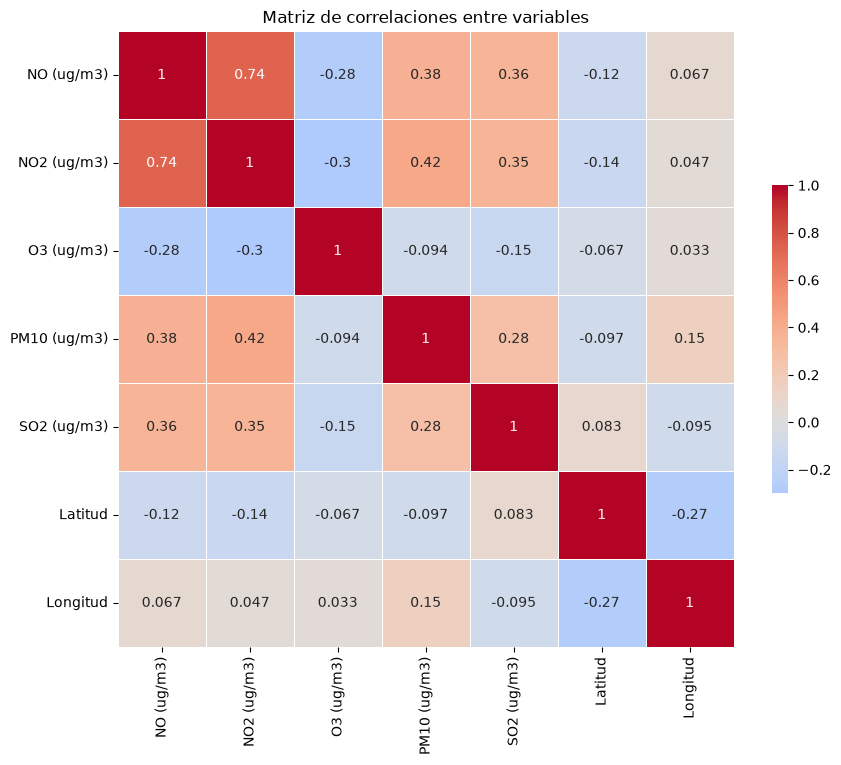

In [55]:
num_variables = calidad_aire.select_dtypes(include=[np.number])

# Calculamos la matriz de coeficientes de correlación entre las variables numéricas
correlacion = num_variables.corr()

# Configuración del gráfico de correlación
plt.figure(figsize=(10, 8))

# Gráfico de correlaciones utilizando un mapa de calor
sns.heatmap(correlacion, annot=True, cmap='coolwarm', center=0, square=True, linewidths=.5, cbar_kws={"shrink": .5})

plt.title('Matriz de correlaciones entre variables')
plt.show()

La *visualización de correlaciones* entre las variables numéricas se ha implementado mediante un mapa de calor (**heatmap**), una herramienta efectiva que permite representar la matriz de correlaciones con un código de colores intuitivo, donde las tonalidades más intensas indican correlaciones más fuertes.    

El análisis de la matriz de correlaciones revela varios patrones interesantes en nuestro conjunto de datos sobre calidad del aire:    

- Las **correlaciones más significativas se observan entre NO (µg/m³) y NO₂ (µg/m³)**, con un coeficiente de r=0.73, sugiriendo una *fuerte asociación positiva*. Esta relación era esperable dado que *ambos contaminantes pertenecen a la familia de los óxidos de nitrógeno (NOx) y comparten fuentes de emisión comunes*, principalmente relacionadas con procesos de combustión.   
- Se identifican también *correlaciones moderadas positivas entre PM10 (µg/m³) y varios contaminantes: con NO (r=0.4) y NO2 (r=0.44)*. Estas asociaciones podrían indicar una contribución común de fuentes de emisión, posiblemente relacionadas con el tráfico urbano o procesos industriales. 



El resto de las variables presentan **coeficientes de correlación más bajos**. Esto se refleja en el gráfico, donde *los cuadrados que representan estas correlaciones tienen un color más cercano al blanco*. Por ejemplo, podríamos inferir que las variables O₃ (µg/m³) y PM10 (µg/m³) son relativamente independientes, ya que su coeficiente de correlación es bajo.

Estas correlaciones observadas **proporcionan una base para comprender las interrelaciones entre contaminantes**, aunque como se ha mencionado anteriormente, deben interpretarse con cautela y en el contexto específico de la calidad del aire urbana.

# CONCLUSIONES.     

El **Análisis Exploratorio de Datos (AED/EDA)** constituye un pilar fundamental en la ciencia de datos moderna, proporcionando un marco metodológico robusto para la comprensión inicial de conjuntos de datos complejos. Como se ha demostrado a lo largo de este notebook, este proceso va más allá de la simple inspección preliminar de datos, constituyendo una fase crítica que determina la calidad y fiabilidad de cualquier análisis posterior, ya sea una investigación científica rigurosa o el desarrollo de visualizaciones interactivas avanzadas.   

La aplicación sistemática de técnicas de AED, desde la verificación de la integridad de los datos hasta el análisis de correlaciones multivariantes, permite construir una base sólida para la toma de decisiones basada en datos.    

Las técnicas presentadas en este notebook constituyen un *punto de partida básico en el análisis de datos*. En aplicaciones más avanzadas, estos métodos pueden y deben complementarse con técnicas más sofisticadas, como el análisis multivariante avanzado, la detección automatizada de anomalías o el uso de técnicas de aprendizaje automático para la exploración de patrones complejos.

# Aprendiendo +.

- [Tutorial EDA con Pandas](https://realpython.com/pandas-python-explore-dataset/)  
- [EDA con Seaborn](https://medium.com/@kosurilindu/try-seaborn-the-ultimate-sea-cret-for-eda-b165fed566a8)